# Lab 5-10：框架地圖——同一個值班任務的六種寫法

**目標**：把模組 5 用過的寫法放在一起比：要寫多少程式、你能控制多少、什麼情況選哪個。這本不呼叫模型，只整理與畫圖。

**你會學到**
- 每種寫法的「最小核心程式」長什麼樣、有幾行
- 控制權與省事程度的取捨
- 一張選型表：情境 → 推薦寫法

**前置**：01～09。

**對應投影片**：「選型：Agent 框架（一）」「選型：Agent 框架（二）」「選型：Agent 與多智能體模式」「模組五小結」

![框架光譜概念圖](images/framework_map.jpg)

*圖：由左到右，自己寫的程式越來越少，能控制的也越來越少。底下都是同一個「模型＋迴圈」；選框架就是決定這條光譜上要站在哪裡。*

## Step 1：每種寫法的最小核心

只取「把查日誌、查指標兩個工具交給模型、跑到有答案為止」這一段，從前面的 notebook 摘出來（不含工具本身與 import）。

In [1]:
CORES = {
    "手寫 ReAct（01）": '''
TOOLS = {"read_logs": (tool_read_logs, "讀日誌", "read_logs: order-api ERROR"), ...}
PROMPT = f"""Thought/Action/PAUSE/Observation 規則…\\n{describe_tools(TOOLS)}"""
messages = [{"role": "system", "content": PROMPT}, {"role": "user", "content": q}]
for step in range(max_steps):
    reply = chat(messages, stop=["PAUSE", "Observation:"])
    messages.append({"role": "assistant", "content": reply})
    if m := ANSWER_RE.search(reply):
        return m.group(1)
    if m := ACTION_RE.search(reply):
        obs = run_action(m.group(1), m.group(2))
    else:
        obs = "格式錯誤，請用 Action: 工具: 參數"
    messages.append({"role": "user", "content": f"Observation: {obs}"})
''',
    "手寫 tool calling（02）": '''
TOOLS = [{"type": "function", "function": {"name": n, "parameters": M.model_json_schema()}} for n, M in ...]
messages = [{"role": "user", "content": q}]
for step in range(max_steps):
    msg = client.chat.completions.create(model=MODEL, messages=messages, tools=TOOLS).choices[0].message
    messages.append(msg.model_dump(exclude_none=True))
    if not msg.tool_calls:
        return msg.content
    for call in msg.tool_calls:
        out = execute(call)
        messages.append({"role": "tool", "tool_call_id": call.id, "content": out})
''',
    "LangGraph（04）": '''
class State(TypedDict):
    messages: Annotated[list, add_messages]
def agent(state): return {"messages": [llm.bind_tools(TOOLS).invoke(state["messages"])]}
def route(state): return "tools" if state["messages"][-1].tool_calls else END
builder = StateGraph(State)
builder.add_node("agent", agent); builder.add_node("tools", ToolNode(TOOLS))
builder.add_edge(START, "agent"); builder.add_conditional_edges("agent", route, ["tools", END])
builder.add_edge("tools", "agent")
graph = builder.compile(checkpointer=InMemorySaver())
graph.invoke({"messages": [("user", q)]}, {"configurable": {"thread_id": "t1"}})
''',
    "deepagents（06）": '''
agent = create_deep_agent(model, tools=[read_logs, query_metrics, restart_service],
    system_prompt="你是值班 agent。", backend=FilesystemBackend(root_dir="workspace"),
    skills=["/skills/"], memory=["/AGENTS.md"], subagents=[log_checker],
    interrupt_on={"restart_service": True}, checkpointer=InMemorySaver())
agent.invoke({"messages": [("user", q)]}, {"configurable": {"thread_id": "t1"}})
''',
    "OpenAI Agents SDK（07）": '''
model = OpenAIChatCompletionsModel(model="qwen2.5:3b", openai_client=AsyncOpenAI(base_url=URL, api_key="ollama"))
agent = Agent(name="oncall", instructions="你是值班助理。", model=model, tools=[read_logs, query_metrics])
result = await Runner.run(agent, q, max_turns=6)
''',
    "Claude Agent SDK（08）": '''
options = ClaudeAgentOptions(system_prompt="你是值班 agent。", mcp_servers={"oncall": oncall_server},
    allowed_tools=["mcp__oncall__read_logs", "mcp__oncall__query_metrics"], max_turns=10)
async for msg in query(prompt=q, options=options):
    print(msg)
''',
    "CrewAI（09）": '''
oncall = Agent(role="值班工程師", goal="找出根因", backstory="只讀不寫", tools=[read_logs, query_metrics], llm=llm)
task = Task(description=q, expected_output="三行：根因、證據、建議", agent=oncall)
result = Crew(agents=[oncall], tasks=[task]).kickoff()
''',
}

LOC = {name: sum(1 for line in code.strip().splitlines() if line.strip()) for name, code in CORES.items()}
for name, n in LOC.items():
    print(f"{name:<24} {n:>2} 行")

手寫 ReAct（01）             13 行
手寫 tool calling（02）      10 行
LangGraph（04）            10 行
deepagents（06）            5 行
OpenAI Agents SDK（07）     3 行
Claude Agent SDK（08）      4 行
CrewAI（09）                3 行


行數越少，代表框架幫你寫得越多。但框架幫你寫的部分，也就是你**看不到、改不動**的部分：
06 我們就花了一整個 Step 去看 deepagents 到底送了什麼給模型。

## Step 2：控制權與適用情境

「控制權」是本課的主觀評分（1～5）：能不能決定每一步做什麼、prompt 長什麼樣、換模型容不容易。

In [2]:
TABLE = [
    # 名稱, 控制權, 換本機模型, 內建的東西, 適合
    ("手寫 ReAct（01）", 5, "容易", "無", "教學、看懂原理；模型不支援 tool calling 時"),
    ("手寫 tool calling（02）", 5, "容易", "無", "小而固定的工具集、需要完全掌握每一步"),
    ("LangGraph（04）", 4, "容易", "狀態、checkpoint、interrupt、時光旅行", "固定流程（審批、ETL）、需要可恢復的長流程"),
    ("deepagents（06）", 3, "要瘦身", "skills、子 agent、檔案記憶、壓縮、審批", "查不完的調查型任務；harness 核心"),
    ("OpenAI Agents SDK（07）", 3, "要改用 ChatCompletions", "guardrail、審批、agent 當工具", "OpenAI 生態、需要 guardrail"),
    ("Claude Agent SDK（08）", 2, "不行（綁 Claude）", "檔案／shell 工具、權限、hooks、MCP、skills", "通用 agent、要用成熟的 Claude Code harness"),
    ("CrewAI（09）", 2, "容易", "角色、任務排程、平行任務", "確定要多 agent（平行查證＋審查）時快速搭"),
]
print(f"{'寫法':<24}{'控制權':<5}{'換本機模型':<14}適合")
for name, ctrl, local, builtin, fit in TABLE:
    print(f"{name:<24}{ctrl:<7}{local:<14}{fit}")

寫法                      控制權  換本機模型         適合
手寫 ReAct（01）            5      容易            教學、看懂原理；模型不支援 tool calling 時
手寫 tool calling（02）     5      容易            小而固定的工具集、需要完全掌握每一步
LangGraph（04）           4      容易            固定流程（審批、ETL）、需要可恢復的長流程
deepagents（06）          3      要瘦身           查不完的調查型任務；harness 核心
OpenAI Agents SDK（07）   3      要改用 ChatCompletionsOpenAI 生態、需要 guardrail
Claude Agent SDK（08）    2      不行（綁 Claude）  通用 agent、要用成熟的 Claude Code harness
CrewAI（09）              2      容易            確定要多 agent（平行查證＋審查）時快速搭


## Step 3：畫成一張地圖

橫軸是核心程式行數（越右寫越多），縱軸是控制權。左下角是「最省事」，右上角是「最自由」。

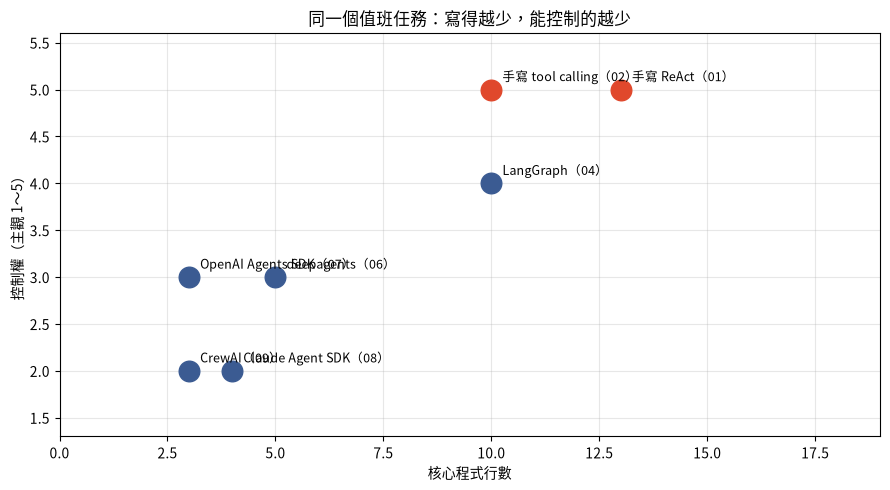

In [3]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

fig, ax = plt.subplots(figsize=(9, 5))
for name, ctrl, *_ in TABLE:
    hand = name.startswith("手寫")
    ax.scatter(LOC[name], ctrl, s=220, color="#e0482c" if hand else "#3b5b92", zorder=3)
    ax.annotate(name, (LOC[name], ctrl), xytext=(8, 6), textcoords="offset points", fontsize=9)
ax.set_xlabel("核心程式行數")
ax.set_ylabel("控制權（主觀 1～5）")
ax.set_ylim(1.3, 5.6)
ax.set_xlim(0, max(LOC.values()) + 6)
ax.grid(alpha=0.3)
ax.set_title("同一個值班任務：寫得越少，能控制的越少")
plt.tight_layout()
plt.show()

## Step 4：選型——情境對寫法

| 情境 | 推薦 | 理由 |
|---|---|---|
| 學原理、面試白板題 | 手寫 tool calling | 20 行就是 agent 的全部 |
| 重啟、改設定、付款等寫入動作 | LangGraph 固定圖＋`interrupt` | 步驟固定、要稽核、要可恢復 |
| 查原因、讀大量日誌與文件 | deepagents（或 Claude Agent SDK） | skills、子 agent、壓縮都現成 |
| 需要輸入／輸出規則檢查 | OpenAI Agents SDK 的 guardrail，或自己寫在圖上 | 規則在模型外面跑 |
| 多個獨立假設要平行查、要獨立審查 | 子 agent（deepagents `task`）或 CrewAI | 依 context／平行／審查切，不依職能切 |
| 只有本機 3B 模型 | 手寫或 LangGraph | prompt 由你控制、最小 |

本課旗艦專案的組合就是表格的第 2、3 列：**外殼是 LangGraph 固定圖（審批 → 執行 → 驗證），核心是一個 harness agent。**

## 試試看

1. 依你自己的標準重打「控制權」分數，重畫地圖。你和同學的排序一樣嗎？
2. 在 `CORES` 加上「LangChain `create_agent`」的寫法（投影片「create_agent 與 middleware」），估它在地圖上的位置。
3. 挑一個你工作上的任務，用 Step 4 的表選一種寫法，寫三句理由。

## 小結

- 所有框架底下都是同一個「模型＋迴圈」；差別在誰寫迴圈、內建了哪些外掛、你還能控制多少。
- 寫入動作用固定圖，調查交給 harness；多 agent 只在 context、平行、審查、權限需要時才拆。
- 模組 5 到這裡結束；模組 6 換個方向：當 prompt 和 RAG 都不夠時，用 LoRA 微調改變模型本身。